# **Oasis Infobyte - Data Science Internship**

# **Name: Maragathavalli C S**

# **Task 5 - Sales Prediction Using Python**

**Objective**

To Build Machine Learning Models that can predict product sales based on advertising expenditure across different media channels such as TV, Radio, and Newspaper.

**Models Used:**

Linear Regression

Polynomial Regression


The objective of this project is to analyze the relationship between advertising expenditure and product sales and develop machine learning models to predict sales.

The project focuses on:

- Understanding the given advertising dataset
- Performing data cleaning and exploratory data analysis
- Visualizing relationships between advertising channels and sales
- Identifying correlations between variables
- Building a Linear Regression model
- Building a Polynomial Regression model as an additional model
- Evaluating both models using regression metrics
- Comparing model performance
- Identifying the better-performing model

**Import Libraries**

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")

#Plotting Style
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


**Load Dataset**

In [4]:
from google.colab import files
uploaded = files.upload()

Saving Advertising.csv to Advertising.csv


In [6]:
df = pd.read_csv("Advertising.csv")

print("Dataset Loaded Successfully!")

Dataset Loaded Successfully!


In [52]:
df.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


In [53]:
df.tail()

,TV,Radio,Newspaper,Sales
195,38.2,3.7,13.8,7.6
196,94.2,4.9,8.1,9.7
197,177.0,9.3,6.4,12.8
198,283.6,42.0,66.2,25.5
199,232.1,8.6,8.7,13.4


In [54]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 200
Number of columns: 4


In [55]:
print("Column names:")
print(df.columns.tolist())

Column names:
['TV', 'Radio', 'Newspaper', 'Sales']


In [56]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


In [57]:
df.describe()

,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,14.022500
std,85.854236,14.846809,21.778621,5.217457
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,10.375000
50%,149.750000,22.900000,25.750000,12.900000
75%,218.825000,36.525000,45.100000,17.400000
max,296.400000,49.600000,114.000000,27.000000


In [58]:
print(df.dtypes)

TV           float64
Radio        float64
Newspaper    float64
Sales        float64
dtype: object


**Data Cleaning**

In [59]:
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64


In [60]:
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


**Check duplicate rows**

In [61]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


**Check for unwanted index columnt**

In [62]:
if "Unnamed: 0" in df.columns:
    df = df.drop(columns=["Unnamed: 0"])

print("Columns after cleaning:")
print(df.columns.tolist())

Columns after cleaning:
['TV', 'Radio', 'Newspaper', 'Sales']


In [64]:
print("Missing values after cleaning:")
print(df.isnull().sum())

print("\nDuplicate rows after cleaning:")
print(df.duplicated().sum())

Missing values after cleaning:
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

Duplicate rows after cleaning:
0


**Exploratory Data Analysis**

In [65]:
print("Sales Statistics")
print("-----------------")
print("Mean:", df["Sales"].mean())
print("Median:", df["Sales"].median())
print("Minimum:", df["Sales"].min())
print("Maximum:", df["Sales"].max())

Sales Statistics
-----------------
Mean: 14.0225
Median: 12.9
Minimum: 1.6
Maximum: 27.0


**Advertising statistics**

In [66]:
df[["TV", "Radio", "Newspaper", "Sales"]].describe()

,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,14.022500
std,85.854236,14.846809,21.778621,5.217457
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,10.375000
50%,149.750000,22.900000,25.750000,12.900000
75%,218.825000,36.525000,45.100000,17.400000
max,296.400000,49.600000,114.000000,27.000000


**Check unique values**

In [67]:
for column in df.columns:
    print(f"{column}: {df[column].nunique()} unique values")

TV: 190 unique values
Radio: 167 unique values
Newspaper: 172 unique values
Sales: 121 unique values


**Distribution of Sales**

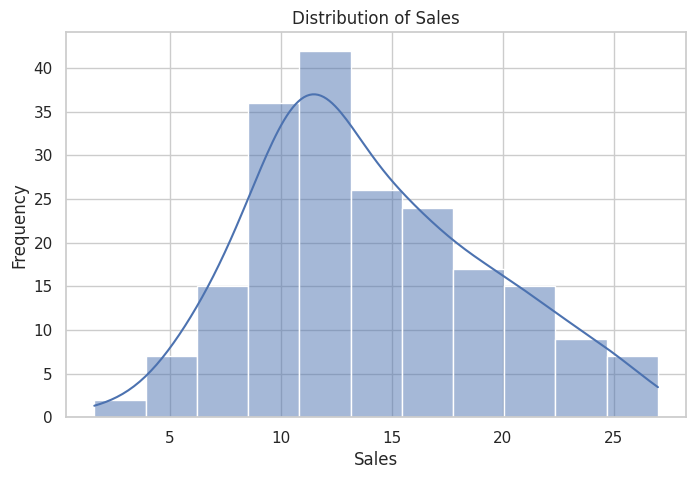

In [68]:
plt.figure(figsize=(8, 5))

sns.histplot(df["Sales"], kde=True)

plt.title("Distribution of Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")

plt.show()

**Data Visualization**

**TV vs Sales**

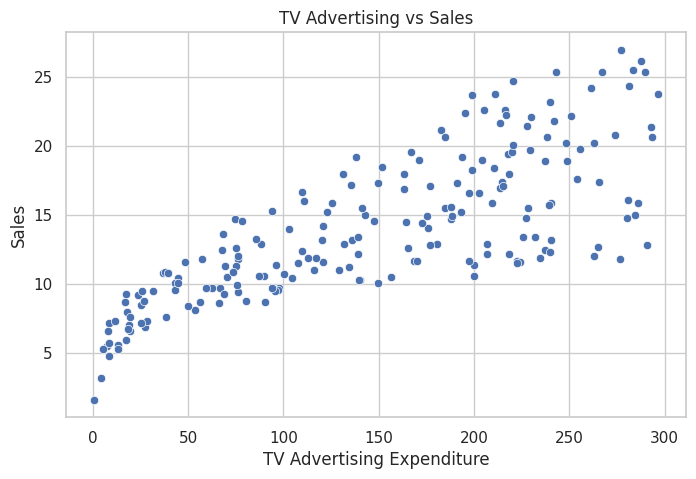

In [69]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="TV",
    y="Sales"
)

plt.title("TV Advertising vs Sales")
plt.xlabel("TV Advertising Expenditure")
plt.ylabel("Sales")

plt.show()

**Radio vs Sales**

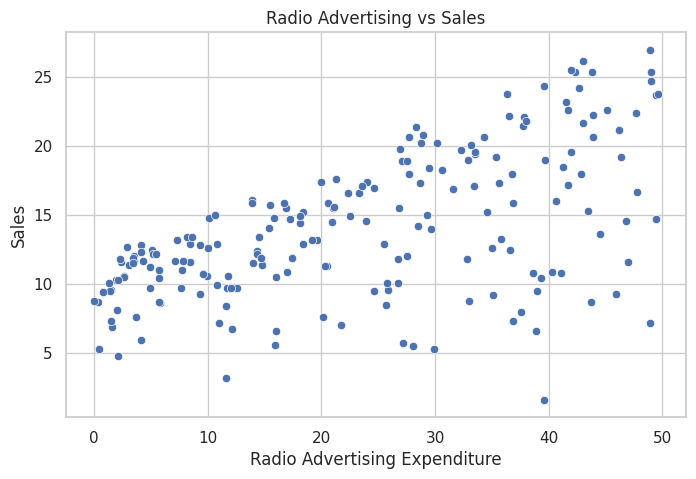

In [70]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Radio",
    y="Sales"
)

plt.title("Radio Advertising vs Sales")
plt.xlabel("Radio Advertising Expenditure")
plt.ylabel("Sales")

plt.show()

**Newspaper vs Sales**

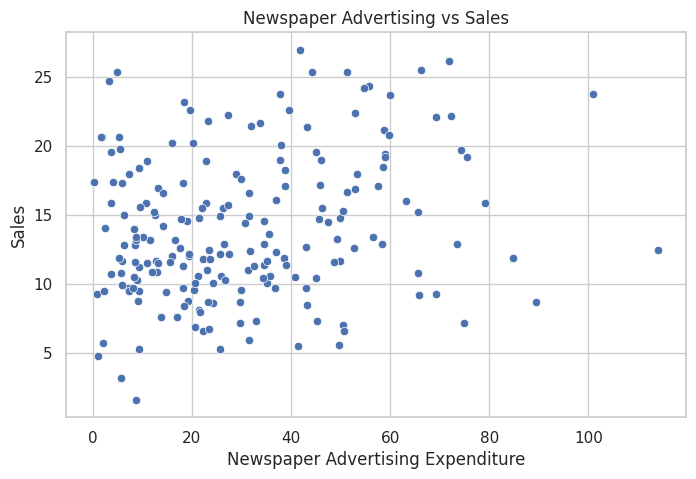

In [71]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Newspaper",
    y="Sales"
)

plt.title("Newspaper Advertising vs Sales")
plt.xlabel("Newspaper Advertising Expenditure")
plt.ylabel("Sales")

plt.show()

**Boxplots**

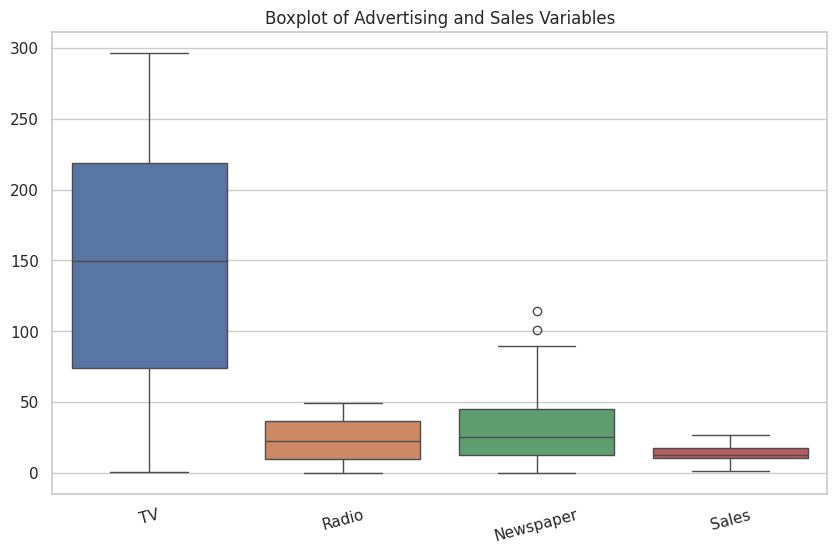

In [72]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=df)

plt.title("Boxplot of Advertising and Sales Variables")
plt.xticks(rotation=15)

plt.show()

**Pairplot**

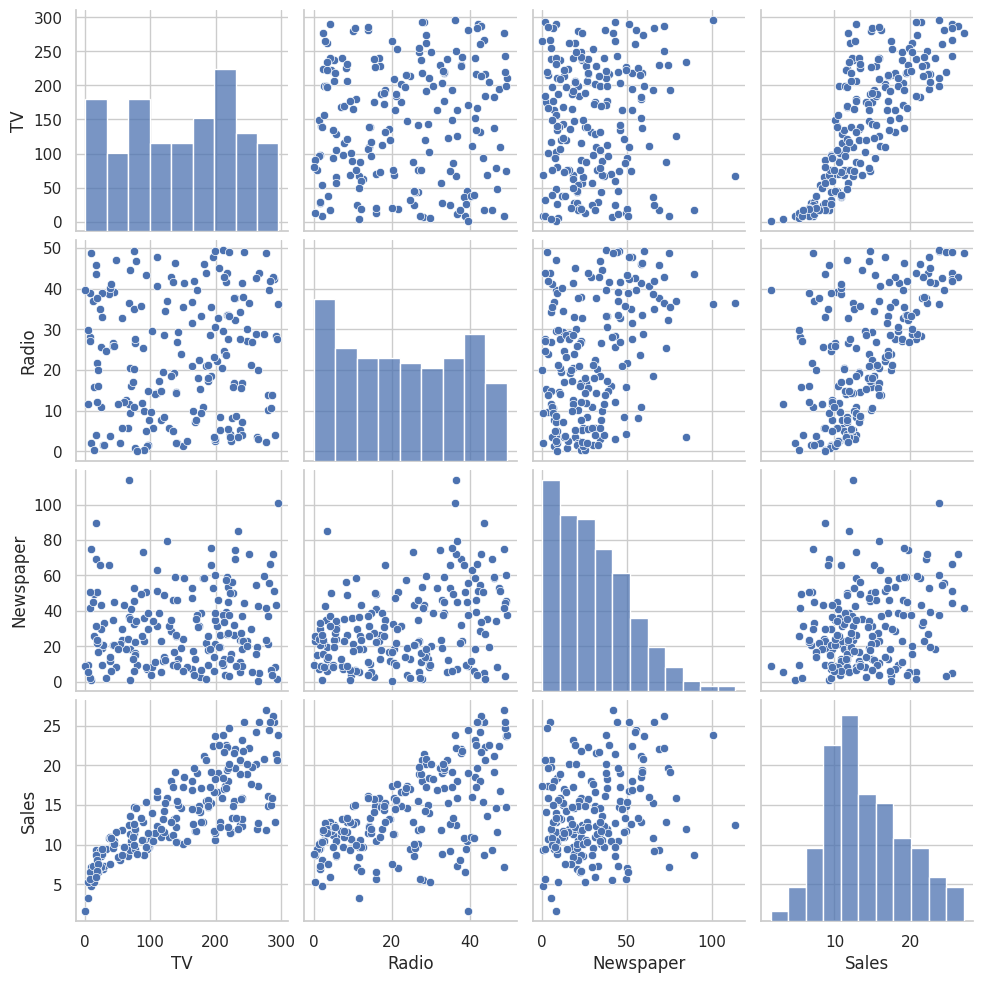

In [73]:
sns.pairplot(df)

plt.show()

**Correlation Analysis**

**Correlation matrix**

In [74]:
correlation_matrix = df.corr(numeric_only=True)

print(correlation_matrix)

                 TV     Radio  Newspaper     Sales
TV         1.000000  0.054809   0.056648  0.782224
Radio      0.054809  1.000000   0.354104  0.576223
Newspaper  0.056648  0.354104   1.000000  0.228299
Sales      0.782224  0.576223   0.228299  1.000000


**Heatmap**

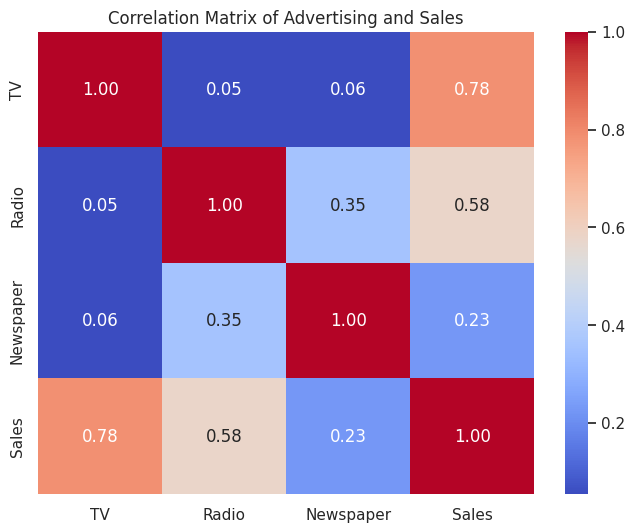

In [75]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix of Advertising and Sales")

plt.show()

**Find correlation with Sales**

In [76]:
sales_correlation = correlation_matrix["Sales"].sort_values(
    ascending=False
)

print("Correlation with Sales:")
print(sales_correlation)

Correlation with Sales:
Sales        1.000000
TV           0.782224
Radio        0.576223
Newspaper    0.228299
Name: Sales, dtype: float64


## **Feature and Target Selection**

The independent variables (features) are:

- TV
- Radio
- Newspaper

The dependent variable (target) is:

- Sales

In [77]:
X = df[["TV", "Radio", "Newspaper"]]

y = df["Sales"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (200, 3)
Target shape: (200,)


**Check features**

In [78]:
X.head()

,TV,Radio,Newspaper
0,230.1,37.8,69.2
1,44.5,39.3,45.1
2,17.2,45.9,69.3
3,151.5,41.3,58.5
4,180.8,10.8,58.4


In [79]:
y.head()

,Sales
0,22.1
1,10.4
2,9.3
3,18.5
4,12.9


**Train-Test Split**

In [80]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (160, 3)
Testing data: (40, 3)


**Linear Regression**

In [81]:
linear_model = LinearRegression()

**Train Model**

In [82]:
linear_model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [83]:
y_pred_linear = linear_model.predict(X_test)

print("First 10 predictions:")
print(y_pred_linear[:10])

First 10 predictions:
[16.4080242  20.88988209 21.55384318 10.60850256 22.11237326 13.10559172
 21.05719192  7.46101034 13.60634581 15.15506967]


**Coefficients**

In [84]:
print("Linear Regression Coefficients:")

for feature, coefficient in zip(X.columns, linear_model.coef_):
    print(f"{feature}: {coefficient:.4f}")

print("\nIntercept:", linear_model.intercept_)

Linear Regression Coefficients:
TV: 0.0447
Radio: 0.1892
Newspaper: 0.0028

Intercept: 2.979067338122629


**Linear Regression Evaluation**

In [85]:
mae_linear = mean_absolute_error(
    y_test,
    y_pred_linear
)

mse_linear = mean_squared_error(
    y_test,
    y_pred_linear
)

rmse_linear = np.sqrt(mse_linear)

r2_linear = r2_score(
    y_test,
    y_pred_linear
)

print("Linear Regression Performance")
print("=" * 40)

print(f"MAE  : {mae_linear:.4f}")
print(f"MSE  : {mse_linear:.4f}")
print(f"RMSE : {rmse_linear:.4f}")
print(f"R²   : {r2_linear:.4f}")

Linear Regression Performance
MAE  : 1.4608
MSE  : 3.1741
RMSE : 1.7816
R²   : 0.8994


**Polynomial Regression**

**Create Polynomial Model**

In [86]:
polynomial_model = Pipeline([
    (
        "polynomial_features",
        PolynomialFeatures(
            degree=2,
            include_bias=False
        )
    ),
    (
        "linear_regression",
        LinearRegression()
    )
])

**Train**

In [87]:
polynomial_model.fit(X_train, y_train)

print("Polynomial Regression model trained successfully!")

Polynomial Regression model trained successfully!


**Predictions**

In [88]:
y_pred_poly = polynomial_model.predict(X_test)

print("First 10 predictions:")
print(y_pred_poly[:10])

First 10 predictions:
[17.25443578 22.7193321  20.42799436  7.542709   24.37103037 12.55927164
 22.80784986  8.34371358 12.0586023  15.69024565]


**Polynomial Regression Evaluation**

In [89]:
mae_poly = mean_absolute_error(
    y_test,
    y_pred_poly
)

mse_poly = mean_squared_error(
    y_test,
    y_pred_poly
)

rmse_poly = np.sqrt(mse_poly)

r2_poly = r2_score(
    y_test,
    y_pred_poly
)

print("Polynomial Regression Performance")
print("=" * 40)

print(f"MAE  : {mae_poly:.4f}")
print(f"MSE  : {mse_poly:.4f}")
print(f"RMSE : {rmse_poly:.4f}")
print(f"R²   : {r2_poly:.4f}")

Polynomial Regression Performance
MAE  : 0.5262
MSE  : 0.4129
RMSE : 0.6426
R²   : 0.9869


**Model Comparison**

In [90]:
model_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Polynomial Regression"
    ],
    "MAE": [
        mae_linear,
        mae_poly
    ],
    "MSE": [
        mse_linear,
        mse_poly
    ],
    "RMSE": [
        rmse_linear,
        rmse_poly
    ],
    "R2 Score": [
        r2_linear,
        r2_poly
    ]
})

model_results

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,1.460757,3.174097,1.781600,0.899438
1,Polynomial Regression,0.526179,0.412910,0.642581,0.986918


# **Determine the best model**

For MAE, MSE and RMSE:
Lower = better

For R²:
Higher = better

In [91]:
best_model = model_results.loc[
    model_results["R2 Score"].idxmax(),
    "Model"
]

print("Best Model based on R² Score:", best_model)

Best Model based on R² Score: Polynomial Regression


**R² comparison**

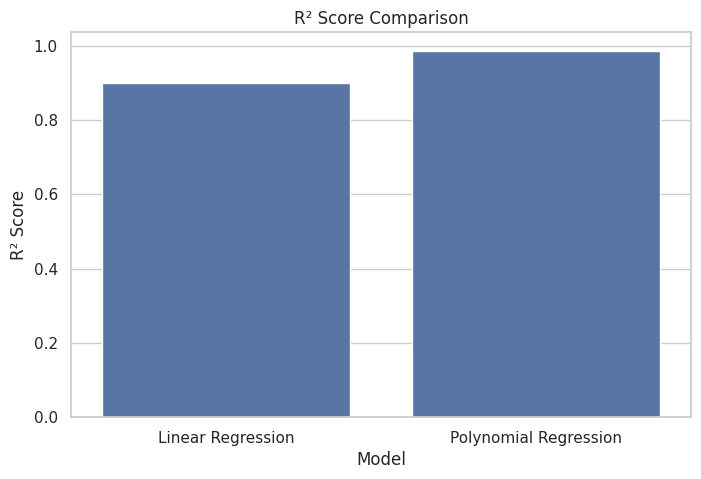

In [92]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=model_results,
    x="Model",
    y="R2 Score"
)

plt.title("R² Score Comparison")
plt.xlabel("Model")
plt.ylabel("R² Score")

plt.show()

**Actual vs Predicted Visualization**

**Linear Regression**

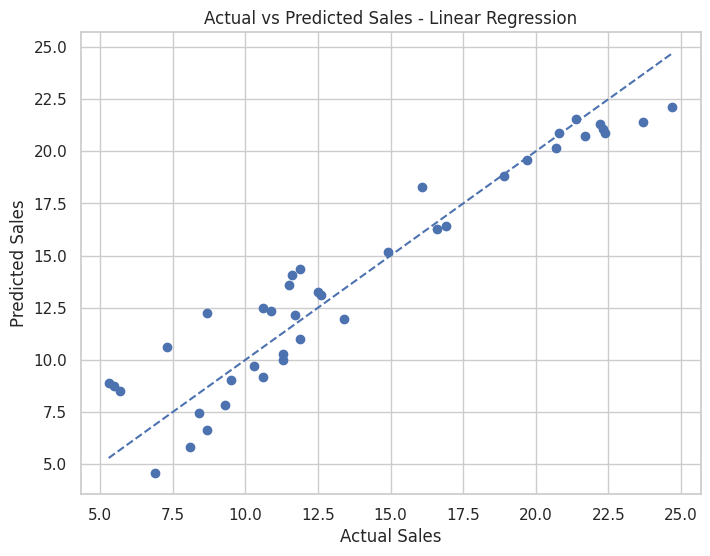

In [93]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_linear
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.title("Actual vs Predicted Sales - Linear Regression")
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")

plt.show()

**Polynomial Regression**

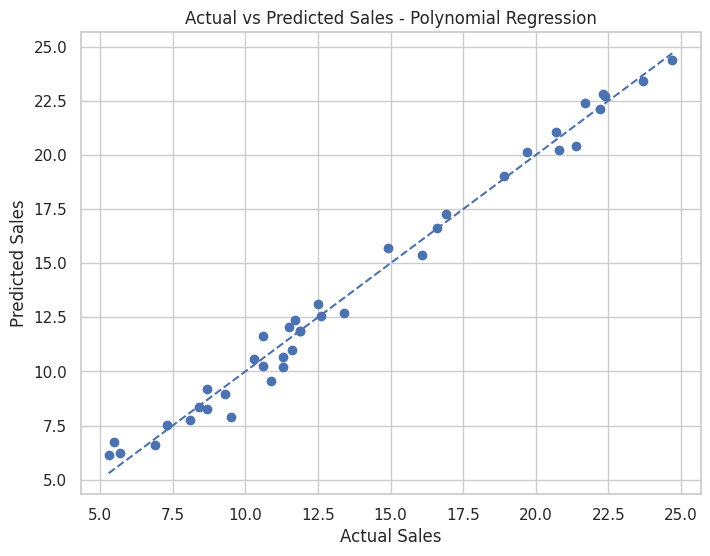

In [94]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_poly
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.title("Actual vs Predicted Sales - Polynomial Regression")
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")

plt.show()

**Combined comparison**

In [95]:
comparison_df = pd.DataFrame({
    "Actual Sales": y_test.values,
    "Linear Regression": y_pred_linear,
    "Polynomial Regression": y_pred_poly
})

comparison_df.head(10)

,Actual Sales,Linear Regression,Polynomial Regression
0,16.9,16.408024,17.254436
1,22.4,20.889882,22.719332
2,21.4,21.553843,20.427994
3,7.3,10.608503,7.542709
4,24.7,22.112373,24.371030
5,12.6,13.105592,12.559272
6,22.3,21.057192,22.807850
7,8.4,7.461010,8.343714
8,11.5,13.606346,12.058602
9,14.9,15.155070,15.690246


**Results & Interpretation**

In [96]:
# Identify the strongest advertising correlation with Sales
correlations = df[["TV", "Radio", "Newspaper", "Sales"]].corr()["Sales"]

feature_correlations = correlations.drop("Sales")

strongest_feature = feature_correlations.abs().idxmax()
strongest_correlation = feature_correlations[strongest_feature]

# Identify the better-performing model based on R² score
if r2_linear >= r2_poly:
    better_model = "Linear Regression"
    better_r2 = r2_linear
    better_rmse = rmse_linear
    better_mae = mae_linear
else:
    better_model = "Polynomial Regression"
    better_r2 = r2_poly
    better_rmse = rmse_poly
    better_mae = mae_poly

print("RESULTS AND INTERPRETATION")
print("=" * 60)

print(
    f"The advertising variable with the strongest relationship "
    f"with Sales is {strongest_feature}, "
    f"with a correlation coefficient of {strongest_correlation:.4f}."
)

print(
    f"\nLinear Regression achieved an R² score of {r2_linear:.4f}, "
    f"with an RMSE of {rmse_linear:.4f} and MAE of {mae_linear:.4f}."
)

print(
    f"Polynomial Regression achieved an R² score of {r2_poly:.4f}, "
    f"with an RMSE of {rmse_poly:.4f} and MAE of {mae_poly:.4f}."
)

print(
    f"\nBased on the R² score, {better_model} performed better."
)

print(
    f"It achieved an R² score of {better_r2:.4f}, "
    f"an RMSE of {better_rmse:.4f}, "
    f"and an MAE of {better_mae:.4f}."
)

print(
    "\nA higher R² score indicates that the model explains a larger "
    "proportion of the variation in sales, while lower MAE and RMSE "
    "indicate smaller prediction errors."
)

RESULTS AND INTERPRETATION
The advertising variable with the strongest relationship with Sales is TV, with a correlation coefficient of 0.7822.

Linear Regression achieved an R² score of 0.8994, with an RMSE of 1.7816 and MAE of 1.4608.
Polynomial Regression achieved an R² score of 0.9869, with an RMSE of 0.6426 and MAE of 0.5262.

Based on the R² score, Polynomial Regression performed better.
It achieved an R² score of 0.9869, an RMSE of 0.6426, and an MAE of 0.5262.

A higher R² score indicates that the model explains a larger proportion of the variation in sales, while lower MAE and RMSE indicate smaller prediction errors.


In [97]:
print("\nModel Performance Comparison:")
display(model_results)


Model Performance Comparison:


,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,1.460757,3.174097,1.781600,0.899438
1,Polynomial Regression,0.526179,0.412910,0.642581,0.986918




## Conclusion

In this project, machine learning techniques were used to predict sales based on advertising expenditure through TV, Radio, and Newspaper.

The dataset was first explored and cleaned, followed by exploratory data analysis, data visualization, and correlation analysis. Among the advertising channels, TV showed the strongest relationship with Sales, with a correlation coefficient of 0.7822.

Two regression models were developed: Linear Regression and Polynomial Regression. The models were evaluated using MAE, MSE, RMSE, and R² Score.

Polynomial Regression performed better than Linear Regression, achieving an R² score of 0.9869, an RMSE of 0.6426, and an MAE of 0.5262.

Overall, the project demonstrates how machine learning can be used to analyze advertising data and predict sales. The results show that Polynomial Regression was more effective for this dataset and can be used to support data-driven sales and advertising decisions.